# Ejercicio de Evaluación de modelos de regresión
![logo Itq](img/ITQ.png)

**Nombre:** Freddy Guevara

**Fecha** *19-11-2026*

**Evaluación de modelos de regresión:** proceso para medir qué tan cerca están las predicciones de un modelo de los valores reales cuando la variable a predecir es un número continuo (por ejemplo, un precio o una temperatura). Para esto usamos métricas de error como el MAE, el MSE, el RMSE y el MAPE: mientras más bajo es el error, mejor es el modelo.

**Link Repositorio** https://github.com/Fguevara92/Fund_Machin_Learn_IA_Noct_26_27/blob/main/Programa4.Ausentes.ipynb

### Importación de librerías
* **numpy** y **pandas**: manejo de arreglos y tablas de datos.
* **sqrt**: raíz cuadrada, la usamos para obtener el RMSE a partir del MSE.
* **pprint**: imprime diccionarios y listas de forma ordenada.
* **datasets**: trae datasets de ejemplo de scikit-learn.
* **DummyRegressor**: modelo base que predice sin aprender (por ejemplo, siempre la media). Sirve como punto de comparación.
* **SVR**: máquina de vectores de soporte para regresión, la versión del SVC que predice números en lugar de clases.
* **cross_validate** y **KFold**: validación cruzada; a diferencia de `cross_val_score`, `cross_validate` permite calcular varias métricas a la vez.
* **train_test_split**: separa los datos en entrenamiento y test.
* **Métricas de error**:
  * `mean_absolute_error` (MAE): promedio de los errores en valor absoluto.
  * `mean_squared_error` (MSE): promedio de los errores al cuadrado; castiga más los errores grandes.
  * `mean_absolute_percentage_error` (MAPE): error promedio expresado en porcentaje.
* **make_scorer**: convierte una métrica en un formato que la validación cruzada pueda usar.
* **preprocessing** y **StandardScaler**: estandarización de los atributos.
* **clone**: crea una copia "limpia" de un modelo, sin entrenar.
* **Pipeline** y **make_pipeline**: unen en un solo objeto varios pasos, como estandarizar y luego entrenar. Así la estandarización se aplica dentro de cada bolsa y se evita la fuga de datos.
* **matplotlib**: para graficar los resultados.

In [1]:
import numpy as np
from math import sqrt
from pprint import pprint
from sklearn import datasets
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.model_selection import KFold
from sklearn.metrics import make_scorer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import pandas as pd
from sklearn.pipeline import Pipeline, make_pipeline

### Carga y exploración de datos
* Cargamos el dataset **Diabetes** con `as_frame=True` para obtenerlo como tabla de pandas.
* Con `head()` mostramos las primeras filas y con `shape` sus dimensiones.
* Los 10 atributos son datos de pacientes: edad, sexo, índice de masa corporal (`bmi`), presión arterial (`bp`) y seis medidas de sangre (`s1` a `s6`). La columna `target` mide la progresión de la diabetes un año después.

In [4]:
# Cargar y explorar los datos
datos = datasets.load_diabetes(as_frame=True)
#pprint(datos)
#print(np.shape(datos.data))
df= datos.frame
display(df.head())
print("Dimensiones", df.shape)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Dimensiones (442, 11)


**Interpretación:** el dataset tiene 442 pacientes y 11 columnas (10 atributos y el target). Los atributos tienen valores pequeños, cercanos a 0, porque scikit-learn ya los entrega escalados. El target sí está en su escala original y va de 25 a 346.

### Separar atributos y variable objetivo
Guardamos los atributos en `X` y el valor a predecir en `y`.

In [5]:
# Extraer la matriz de datos "X" y la variable target "y"
X = datos.data
y = datos.target

### Partición externa: hold out 80-20%
Separamos el 20% de los datos para test y el 80% para entrenamiento.

In [6]:
# Partición EXTERNA: hold-out split 80% train - 20% test.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)
print ("Datos de entrenamiento: ", X_train.shape)
print("Datos de test. ", X_test.shape)

Datos de entrenamiento:  (353, 10)
Datos de test.  (89, 10)


**Interpretación:** quedan 353 pacientes para entrenamiento y 89 para test, cada uno con 10 atributos.

### Estandarizador
Creamos el `StandardScaler`. Todavía no lo aplicamos: lo vamos a incluir dentro del pipeline del modelo.

In [7]:
# Estandarización de los datos de entrenamiento y test
standarizer = preprocessing.StandardScaler()

### Métricas de evaluación
Definimos un diccionario con tres métricas de error:
* **MAE**: error absoluto promedio, en las mismas unidades del target.
* **RMSE**: raíz del error cuadrático medio. Castiga más los errores grandes.
* **MAPE**: error promedio en porcentaje respecto al valor real.

Con `make_scorer` y `greater_is_better=False` le indicamos a scikit-learn que en estas métricas un valor **más bajo es mejor**.

In [8]:
# Métricas de evaluación.
metricas = {
  'MAE': 'neg_mean_absolute_error',
  'RMSE': make_scorer(lambda y, y_pred:
                      sqrt(mean_squared_error(y, y_pred)),
                      greater_is_better=False),
  'MAPE': make_scorer(lambda y, y_pred:
                      np.mean(np.abs((y - y_pred) / y)) * 100,
                      greater_is_better=False)}

### Definición del modelo con Pipeline
Unimos en un **Pipeline** dos pasos: la estandarización y el modelo **SVR** (regresión con vectores de soporte).
* `C=10`: controla la regularización. Un valor alto permite que el modelo se ajuste más a los datos.
* `kernel='rbf'`: permite encontrar relaciones no lineales.
* `gamma='scale'`: ajusta automáticamente la influencia de cada punto según los datos.

Al usar Pipeline, la estandarización se aprende dentro de cada bolsa de la validación cruzada, y así se evita la fuga de datos.

In [10]:
# Definimos un algoritmo SVM de regresión
alg = Pipeline([
    ("standarizer", standarizer),
    ("regresion", SVR(C=10, gamma = "scale", kernel="rbf"))
    ])

### Validación cruzada interna
Con `cross_validate` evaluamos el modelo con **5 bolsas** sobre el entrenamiento. `shuffle=True` mezcla los datos y `random_state=42` hace que el resultado sea repetible. A diferencia de `cross_val_score`, aquí calculamos las tres métricas a la vez.

In [11]:
# Validación y evaluación del modelo.
# en "cv = KFold(n_splits=5)" se hace un cross-validation INTERNO!! 
results = cross_validate(alg, X_train, y_train, cv = KFold(n_splits=5, shuffle=True, random_state=42), scoring = metricas)

### Resultados de la validación cruzada
Mostramos con `pprint` los tiempos de entrenamiento y evaluación, y el error de cada métrica en cada bolsa.

In [12]:
# Presentación de los resultados de la evaluación.
pprint(results)

{'fit_time': array([0.10452104, 0.02105212, 0.01826787, 0.01881456, 0.02676153]),
 'score_time': array([0.01198125, 0.01173806, 0.01243162, 0.01273155, 0.01514006]),
 'test_MAE': array([-48.26285616, -51.99094138, -42.19909846, -45.73437715,
       -50.39789838]),
 'test_MAPE': array([-32.83110657, -45.90028442, -37.74947192, -43.12401136,
       -44.16570536]),
 'test_RMSE': array([-57.68310314, -60.27338482, -51.94585761, -55.51382769,
       -63.98279561])}


**Interpretación:** los errores salen **negativos** porque scikit-learn invierte el signo de las métricas donde menor es mejor. Lo que importa es el valor absoluto. En promedio, las 5 bolsas dan:
* MAE ≈ **47,7**
* RMSE ≈ **57,9**
* MAPE ≈ **40,8%**

Los valores son parecidos entre bolsas (desviación de unos 3 a 5 puntos), así que el modelo es estable.

### Entrenamiento del modelo final
Con los hiperparámetros elegidos, entrenamos un nuevo SVR con todos los datos de entrenamiento para luego evaluarlo con el test.

In [13]:
# Una vez hemos optimizado los hiperparámetros en el conjunto de validación, entrenamos un nuevo modelo que contenga
# todos los datos de entrenamiento (es decir, train + validation) para evaluar el test
model = SVR(C=10, gamma='scale', kernel='rbf')
model = model.fit(X_train, y_train)

### Evaluación en test
Predecimos los valores del test y calculamos las tres métricas de error.

In [16]:
# Extraemos el error absoluto promedio (MAE) del conjunto de test
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)

print('Test results (MAE): ', mae)
print("Test results (RMSE); ", round(sqrt(mean_squared_error(y_test, y_pred)), 3))
print("Test results (MAPE): ", round(mean_absolute_percentage_error(y_test, y_pred)*100, 3))

Test results (MAE):  41.24319704038717
Test results (RMSE);  51.766
Test results (MAPE):  36.298


**Interpretación:**
* **MAE = 41,24**: en promedio, el modelo se equivoca unas 41 unidades de progresión de la enfermedad.
* **RMSE = 51,77**: es mayor que el MAE porque hay algunos errores grandes que pesan más.
* **MAPE = 36,30%**: en promedio, la predicción se desvía un 36% del valor real.

Los errores en test son un poco menores que en la validación cruzada, lo que indica que el modelo generaliza bien. Aun así, el error es considerable: con solo estos 10 atributos, la progresión de la diabetes es difícil de predecir con precisión.

### Comparación de predicciones y valores reales
Mostramos las 10 primeras predicciones junto a sus valores reales para ver cuánto difieren.

In [15]:
# También podemos extraer las predicciones para cuánto difieren los valores predichos de los reales
print('Predicciones:   ', np.round(y_pred[:10], 1))
print('Valores reales: ', y_test[:10])

Predicciones:    [149.2 171.7 152.8 213.1 110.4 122.3 227.6 192.2 106.2 103.3]
Valores reales:  287    219.0
211     70.0
72     202.0
321    230.0
73     111.0
418     84.0
367    242.0
354    272.0
281     94.0
148     96.0
Name: target, dtype: float64


**Interpretación:** algunas predicciones están cerca del valor real, como 110,4 frente a 111 o 192,2 frente a 272... [ajústalo con tus casos]. Otras se alejan bastante, como 149,2 frente a 219. Además, el modelo tiende a dar valores intermedios: le cuesta predecir casos muy bajos o muy altos. Los números de la izquierda en los valores reales son el índice de cada paciente en la tabla original.

### Función para graficar real vs. predicción
Definimos una función que dibuja un diagrama de dispersión: en el eje X va el valor real y en el eje Y la predicción. La línea punteada diagonal representa la **predicción perfecta** (predicción = valor real).

In [18]:
# Grafica de realidad -vs- prediccion.
def grafica_real_vs_pred(y_true, y_pred, metricas, algoritmo):
    fig, ax = plt.subplots()
    ax.scatter(y_true, y_pred, edgecolors=(0, 0, 0))
    ax.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'k--', lw=4)
    ax.set_xlabel('Valor real de la clase')
    ax.set_ylabel('Predicción')
    plt.show()

### Gráfica real vs. predicción
Llamamos a la función con los datos de test para ver el comportamiento del modelo.

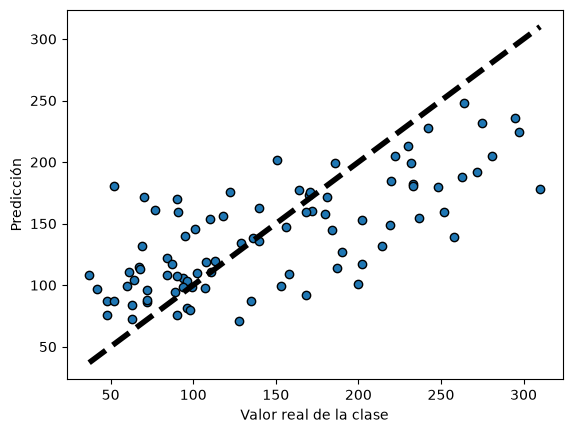

In [19]:
grafica_real_vs_pred(y_test, y_pred, metricas, model)

**Interpretación:** algunas predicciones están muy cerca del valor real, como 110,4 frente a 111, 227,6 frente a 242 o 103,3 frente a 96. Otras se alejan bastante, como 171,7 frente a 70 o 192,2 frente a 272. El modelo tiende a dar valores intermedios y le cuesta predecir los casos muy bajos o muy altos. Los números de la izquierda en los valores reales son el índice de cada paciente en la tabla original.